# Netflix Content Library: EDA, Statistical Summaries & Trend Analysis

**Dataset:** `netflix_titles_cleaned.csv` (one row per title)  
**Role:** Member 2 – Exploratory Data Analysis (EDA), statistical summaries and trend analysis

This notebook answers five questions. For each one you get: (1) a short explanation of the method, (2) commented code, (3) the output, and (4) a plain-language interpretation.

| # | Question | Column(s) |
|---|----------|-----------|
| 1 | How has the content library changed over time? | `date_added` |
| 2 | Are Movies or TV Shows more common? | `type` |
| 3 | Which countries contribute the most content? | `country` |
| 4 | Which genres dominate the library? | `listed_in` |
| 5 | How has the distribution of release years changed? | `release_year` |

**How to run:** put this notebook in the same folder as `netflix_titles_cleaned.csv`, then use *Kernel → Restart & Run All*. Required packages: `pandas`, `numpy`, `matplotlib`, `scipy`.

## 0. Setup

**What the code does**
- Imports the libraries: `pandas` for tables, `numpy` for numbers, `matplotlib` for charts, `scipy.stats` for statistical tests.
- Defines a small colour palette and a helper `style_ax()` so every chart looks consistent (no top/right border, light grid, muted tick labels).
- `%matplotlib inline` makes charts appear directly under the cell that draws them.

In [1]:
%matplotlib inline
import warnings
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

# ---- Chart styling (one place to change the look of every chart) ----
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
SERIES = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]   # fixed order for multi-line charts
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e3e2de"

plt.rcParams.update({
    "figure.dpi": 100, "savefig.facecolor": "white", "figure.facecolor": "white",
    "font.size": 10, "text.color": INK, "axes.labelcolor": MUTED,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def style_ax(ax, grid_axis="y"):
    """Minimal axes: hide top/right spines, light grid on one axis, muted ticks."""
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0)

DATA_PATH = "netflix_titles_cleaned.csv"   # change if the file lives elsewhere

## 1. Load the data and first EDA checks

**What the code does**
1. `pd.read_csv` loads the file into a DataFrame called `df`.
2. `df.info()` shows each column's data type and how many values are non-null.
3. We count **real missing values** (`NaN`) and also the placeholder text **`"Unknown"`** that the cleaning step used for director, cast, country and rating. Both mean "we don't know", but they look different to pandas, so we check for both.
4. We check for duplicate rows (same `show_id`, and same title/type/release year).
5. `date_added` is stored as text, so we convert it to a real date with `pd.to_datetime`, then pull out `year_added` and `month_added`. These drive Question 1.

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", df.shape)
print()
df.info()

Shape (rows, columns): (8807, 13)

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   show_id       8807 non-null   str    
 1   type          8807 non-null   str    
 2   title         8807 non-null   str    
 3   director      8807 non-null   str    
 4   cast          8807 non-null   str    
 5   country       8807 non-null   str    
 6   date_added    8797 non-null   str    
 7   release_year  8807 non-null   int64  
 8   rating        8807 non-null   str    
 9   duration      8807 non-null   str    
 10  listed_in     8807 non-null   str    
 11  description   8807 non-null   str    
 12  year_added    8797 non-null   float64
dtypes: float64(1), int64(1), str(11)
memory usage: 894.6 KB


In [3]:
# ---- Missing values: real NaN vs the "Unknown" placeholder ----
text_cols = [c for c in df.columns if c not in ("release_year", "year_added")]
quality = pd.DataFrame({
    "missing_NaN": df.isna().sum(),
    "unknown_placeholder": [(df[c] == "Unknown").sum() if c in text_cols else 0 for c in df.columns],
})
quality["total_unknown_%"] = ((quality.sum(axis=1)) / len(df) * 100).round(2)
print(quality[quality.sum(axis=1) > 0])

# ---- Duplicates ----
print("\nDuplicate show_id values:", df.duplicated("show_id").sum())
print("Duplicate (title, type, release_year):", df.duplicated(["title", "type", "release_year"]).sum())

# ---- Parse dates ----
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")
df["year_added"] = df["date_added"].dt.year.astype("Int64")     # Int64 keeps missing values as <NA>
df["month_added"] = df["date_added"].dt.month.astype("Int64")
print("\nDate range of date_added:", df["date_added"].min().date(), "->", df["date_added"].max().date())
print("Rows with no date_added:", df["date_added"].isna().sum())

            missing_NaN  unknown_placeholder  total_unknown_%
title                 0                    1             0.01
director              0                 2634            29.91
cast                  0                  825             9.37
country               0                  831             9.44
date_added           10                    0             0.11
rating                0                    7             0.08
year_added           10                    0             0.11

Duplicate show_id values: 0
Duplicate (title, type, release_year): 1

Date range of date_added: 2008-01-01 -> 2021-09-25
Rows with no date_added: 10



**Reading the output**
- No duplicate `show_id`s, and only one repeated title/type/year combination, so duplicates are not a concern.
- Real missing values are rare: only **10 rows (0.1 %) have no `date_added`** (all TV Shows). They are left out of Question 1 only.
- The `"Unknown"` placeholder is much more common: **director 29.9 %**, **country 9.4 %**, **cast 9.4 %**. `director` and `cast` are not used in the five questions, but `country` is, so we exclude `"Unknown"` in Question 3.
- The data runs from **2008-01-01 to 2021-09-25**, so anything about 2021 covers only ~9 months.


In [4]:
# ---- Statistical summary of numeric + categorical columns ----
display_cols = ["release_year", "year_added"]
print(df[display_cols].describe().round(2))
print()
print(df[["type", "rating"]].describe())
print("\nTop ratings:\n", df["rating"].value_counts().head(8))

       release_year  year_added
count       8807.00      8797.0
mean        2014.18     2018.87
std            8.82        1.57
min         1925.00      2008.0
25%         2013.00      2018.0
50%         2017.00      2019.0
75%         2019.00      2020.0
max         2021.00      2021.0

         type rating
count    8807   8807
unique      2     15
top     Movie  TV-MA
freq     6131   3207

Top ratings:
 rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
Name: count, dtype: int64



**Reading the output:** the median `release_year` is **2017** while the minimum is **1925**; the average (2014) sits well below the median, a first hint that the distribution has a long tail of old titles (explored in Question 5). Most titles were added in 2018–2020 (median `year_added` = 2019).


## Question 1 – How has Netflix's content library changed over time?

**Column:** `date_added` → **Analysis:** count titles added per year.

**What the code does**
- `groupby("year_added").size()` counts titles per year; `.reindex(...)` makes sure no year is silently skipped.
- **Year-over-year (YoY) change** uses `.diff()` (absolute change) and `.pct_change()` (percentage change).
- **Cumulative total** (`.cumsum()`) shows how the library grew in size.
- **Compound annual growth rate (CAGR)** = `(end / start) ** (1 / years) - 1`, a single number for the average growth speed during the expansion.
- A **linear regression** (`stats.linregress`) over 2015–2019 estimates how many *extra* titles per year Netflix added on average.

> The data ends on the last `date_added` shown above, so **2021 is a partial year**. Comparing it with full years is misleading, so we also do a **like-for-like comparison** (January 1 up to the same calendar day in every year).

In [5]:
first_year, last_year = int(df["year_added"].min()), int(df["year_added"].max())

yearly = (df.groupby("year_added").size()
            .reindex(range(first_year, last_year + 1), fill_value=0)
            .rename("titles_added").to_frame())
yearly.index = yearly.index.astype(int)
yearly.index.name = "year_added"

yearly["yoy_change"] = yearly["titles_added"].diff()
yearly["yoy_pct"] = (yearly["titles_added"].pct_change() * 100).round(1)
yearly["cumulative"] = yearly["titles_added"].cumsum()
yearly["share_of_library_%"] = (yearly["titles_added"] / yearly["titles_added"].sum() * 100).round(1)
yearly

,titles_added,yoy_change,yoy_pct,cumulative,share_of_library_%
year_added,,,,,
2008,2,NaN,NaN,2,0.0
2009,2,0.0,0.0,4,0.0
2010,1,-1.0,-50.0,5,0.0
2011,13,12.0,1200.0,18,0.1
2012,3,-10.0,-76.9,21,0.0
2013,11,8.0,266.7,32,0.1
2014,24,13.0,118.2,56,0.3
2015,82,58.0,241.7,138,0.9
2016,429,347.0,423.2,567,4.9


In [6]:
total = yearly["titles_added"].sum()
peak_year = yearly["titles_added"].idxmax()

print(f"Titles with a valid date_added : {total:,}")
print(f"Peak year                      : {peak_year} ({yearly.loc[peak_year, 'titles_added']:,} titles)")
print(f"Added up to and including 2015 : {yearly.loc[:2015, 'titles_added'].sum():,} "
      f"({yearly.loc[:2015, 'titles_added'].sum() / total:.1%})")
print(f"Added 2016-2019 (expansion)    : {yearly.loc[2016:2019, 'titles_added'].sum():,} "
      f"({yearly.loc[2016:2019, 'titles_added'].sum() / total:.1%})")

# CAGR from 2016 to 2019 (2015 is used only for the regression: its tiny base would inflate a CAGR)
cagr = (yearly.loc[2019, "titles_added"] / yearly.loc[2016, "titles_added"]) ** (1 / 3) - 1
print(f"CAGR of yearly additions 2016->2019 : {cagr:.1%} per year")

# Linear trend during the expansion phase (2015-2019)
phase = yearly.loc[2015:2019, "titles_added"]
lr = stats.linregress(phase.index, phase.values)
print(f"Linear trend 2015-2019: +{lr.slope:,.0f} titles per year, R^2 = {lr.rvalue**2:.3f}, p = {lr.pvalue:.4f}")

# Change after the peak, full years only
chg = yearly.loc[2020, "titles_added"] / yearly.loc[2019, "titles_added"] - 1
print(f"2019 -> 2020 change (both full years): {chg:+.1%}")

Titles with a valid date_added : 8,797
Peak year                      : 2019 (2,016 titles)
Added up to and including 2015 : 138 (1.6%)
Added 2016-2019 (expansion)    : 5,282 (60.0%)
CAGR of yearly additions 2016->2019 : 67.5% per year
Linear trend 2015-2019: +509 titles per year, R^2 = 0.984, p = 0.0009
2019 -> 2020 change (both full years): -6.8%



**Interpretation**
- **Slow start, then a sudden expansion.** Only 138 titles (1.6 %) were added up to 2015, but **2016–2019 alone account for 60 % of everything** in the data.
- **The growth was very steep and almost perfectly linear in 2015–2019:** about **+509 extra titles every year** (R² = 0.98), equivalent to roughly **67 % compound annual growth** from 2016 to 2019.
- **Peak in 2019 (2,016 titles)**, followed by a **6.8 % drop in 2020**. (A CAGR starting at 2015 would be ≈ 120 %+, but that is inflated by the tiny 2015 base, so we start at 2016.)


In [7]:
# ---- Like-for-like: January 1 -> same calendar day as the last date in the data ----
cutoff = df["date_added"].max()
cutoff_doy = cutoff.dayofyear
ytd = (df[df["date_added"].dt.dayofyear <= cutoff_doy]
         .groupby("year_added").size().loc[2016:2021].rename("titles_added_YTD").to_frame())
ytd["yoy_pct"] = (ytd["titles_added_YTD"].pct_change() * 100).round(1)
print(f"Titles added from Jan 1 to {cutoff.strftime('%b %d')} of each year:")
ytd

Titles added from Jan 1 to Sep 25 of each year:


,titles_added_YTD,yoy_pct
year_added,,
2016,237,NaN
2017,844,256.1
2018,1097,30.0
2019,1340,22.2
2020,1357,1.3
2021,1498,10.4



**Interpretation:** this like-for-like view corrects the misleading 2021 bar. Over the same Jan 1 – Sep 25 window, **2021 (1,498 titles) is actually 10.4 % *higher* than 2020 (1,357)**, and 2020 was only 1.3 % above 2019. So the apparent 2020–2021 "decline" in the raw yearly chart comes mainly from 2021 being incomplete; additions have **levelled off at a high plateau**, not collapsed. (The 2020 full-year dip happened in the last quarter: 2020 YTD was flat vs 2019, but the full year was 6.8 % lower.)


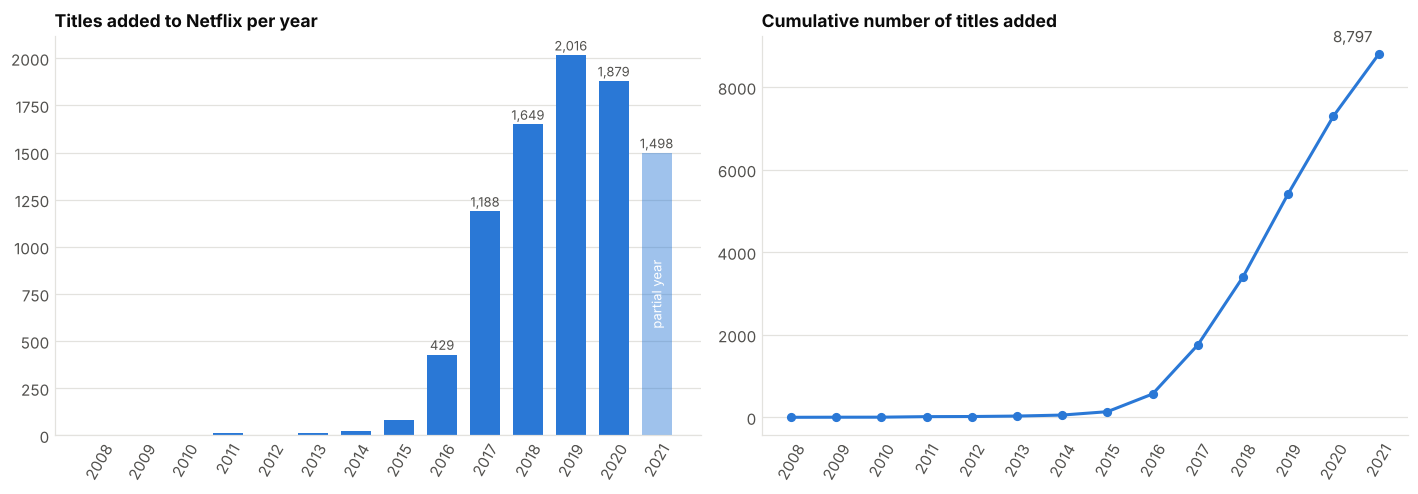

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# (a) Titles added per year (2021 drawn lighter: partial year)
ax = axes[0]
colors = [BLUE] * len(yearly)
bars = ax.bar(yearly.index, yearly["titles_added"], color=colors, width=0.7)
bars[-1].set_alpha(0.45)                       # 2021 is partial
ax.set_title("Titles added to Netflix per year")
ax.set_xticks(yearly.index); ax.set_xticklabels(yearly.index, rotation=60)
for x, v in yearly.loc[2016:, "titles_added"].items():     # label only the recent years
    ax.text(x, v + 25, f"{v:,}", ha="center", fontsize=8.5, color=MUTED)
ax.text(2021, yearly.loc[2021, "titles_added"] / 2, "partial year", rotation=90, ha="center", va="center", fontsize=8.5, color="white")
style_ax(ax)

# (b) Cumulative library size
ax = axes[1]
ax.plot(yearly.index, yearly["cumulative"], color=BLUE, linewidth=2, marker="o", markersize=5)
ax.set_title("Cumulative number of titles added")
ax.set_xticks(yearly.index); ax.set_xticklabels(yearly.index, rotation=60)
ax.annotate(f"{yearly['cumulative'].iloc[-1]:,}", (yearly.index[-1], yearly["cumulative"].iloc[-1]),
            textcoords="offset points", xytext=(-4, 8), ha="right", color=MUTED)
style_ax(ax)
plt.tight_layout(); plt.show()


**Interpretation:** the left chart shows the "hockey-stick" shape: near-zero until 2015, a steep climb to 2019, then a plateau. The right chart shows the same story as library size: ~8,800 titles in total, with the steepest growth between 2016 and 2019. The lighter 2021 bar is a partial year.


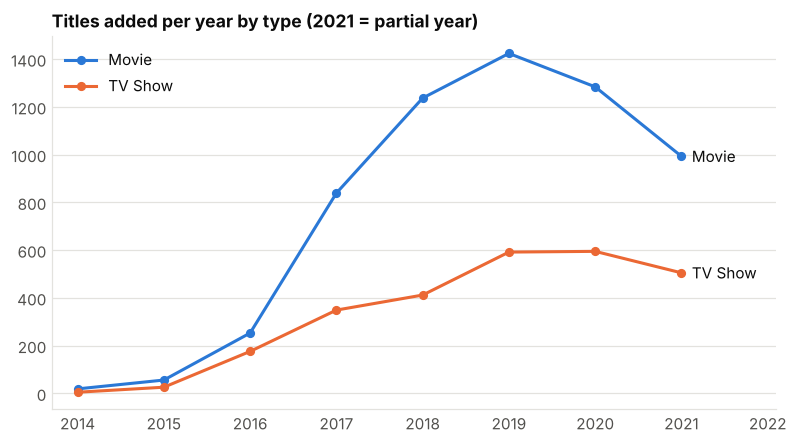

type,Movie,TV Show
year_added,,
2014,19,5
2015,56,26
2016,253,176
2017,839,349
2018,1237,412
2019,1424,592
2020,1284,595
2021,993,505


In [9]:
# ---- Movies vs TV Shows added per year (2014 onward; earlier years have only a handful of titles) ----
by_type = pd.crosstab(df["year_added"], df["type"]).loc[2014:]
by_type.index = by_type.index.astype(int)

fig, ax = plt.subplots(figsize=(8.5, 4.4))
for col, colour in (("Movie", BLUE), ("TV Show", ORANGE)):
    ax.plot(by_type.index, by_type[col], color=colour, linewidth=2, marker="o", markersize=5, label=col)
    ax.text(by_type.index[-1] + 0.12, by_type[col].iloc[-1], col, color=INK, va="center")   # direct label
ax.set_title("Titles added per year by type (2021 = partial year)")
ax.set_xlim(by_type.index[0] - 0.3, by_type.index[-1] + 1.1)
ax.legend(frameon=False, loc="upper left")
style_ax(ax)
plt.show()
by_type


**Interpretation:** both formats followed the same boom-and-plateau pattern, but **Movies drive the volume** (peak 2019 with 1,424), whereas **TV Show additions held steady at ~590–595 in 2019 and 2020** before the partial-year 2021. Movies were added at about 2–3× the rate of TV Shows in every year from 2017.


Busiest month : Dec (783 titles)
Quietest month: Feb (446 titles)


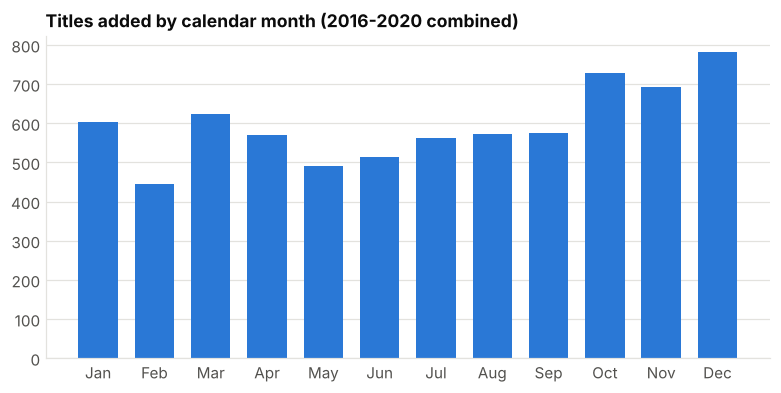

In [10]:
# ---- Seasonality: which calendar months receive most additions? (complete years 2016-2020 only) ----
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
m = (df[df["year_added"].between(2016, 2020)]
       .groupby("month_added").size().reindex(range(1, 13)))

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.bar(months, m.values, color=BLUE, width=0.7)
ax.set_title("Titles added by calendar month (2016-2020 combined)")
style_ax(ax)
plt.show()
print("Busiest month :", months[m.idxmax() - 1], f"({m.max():,} titles)")
print("Quietest month:", months[m.idxmin() - 1], f"({m.min():,} titles)")


**Interpretation:** additions are not evenly spread over the year. **October–December are the busiest months (December highest with 783 titles)** and **February is the quietest (446)**. This suggests a modest seasonal pattern, with more content landing towards the end of the year. This is observational only; the data cannot say *why*.


## Question 2 – Are Movies or TV Shows more common?

**Column:** `type` → **Analysis:** compare counts and percentages.

**What the code does**
- `value_counts()` gives the count of each type; `normalize=True` gives proportions.
- A **binomial test** (`stats.binomtest`) asks: *if Movies and TV Shows were equally likely (50/50), how surprising is this split?* A tiny p-value means the imbalance is real, not chance.
- We then look at how the **share of TV Shows changes by year added** and test whether `type` and the period are statistically related using a **chi-square test of independence** (with **Cramér's V** as the effect size, where 0 = no relation, 1 = perfect relation).
- Finally, we summarise typical **movie runtime** (minutes) and **number of TV seasons** by extracting the digits from the `duration` text.

In [11]:
type_counts = df["type"].value_counts()
type_pct = df["type"].value_counts(normalize=True).mul(100).round(2)
summary_type = pd.DataFrame({"titles": type_counts, "percent": type_pct})
print(summary_type)

n, k = len(df), type_counts["Movie"]
print(f"\nMovies per TV Show: {type_counts['Movie'] / type_counts['TV Show']:.2f}")
bt = stats.binomtest(k, n, 0.5)
print(f"Binomial test vs 50/50: Movie share = {k/n:.1%}, 95% CI "
      f"[{bt.proportion_ci().low:.1%}, {bt.proportion_ci().high:.1%}], p = {bt.pvalue:.2e}")

         titles  percent
type                    
Movie      6131    69.62
TV Show    2676    30.38

Movies per TV Show: 2.29
Binomial test vs 50/50: Movie share = 69.6%, 95% CI [68.6%, 70.6%], p = 1.37e-304



**Interpretation:** **Movies clearly dominate: 6,131 titles (69.6 %) vs 2,676 TV Shows (30.4 %)**, i.e. about **2.3 movies for every TV show**. The binomial test confirms this is far from a 50/50 split (p ≈ 10⁻³⁰⁴; 95 % CI for the Movie share: 68.6 %–70.6 %). With 8,807 titles, even small gaps are significant, so the *size* of the gap (≈ 39 percentage points) is the important finding.


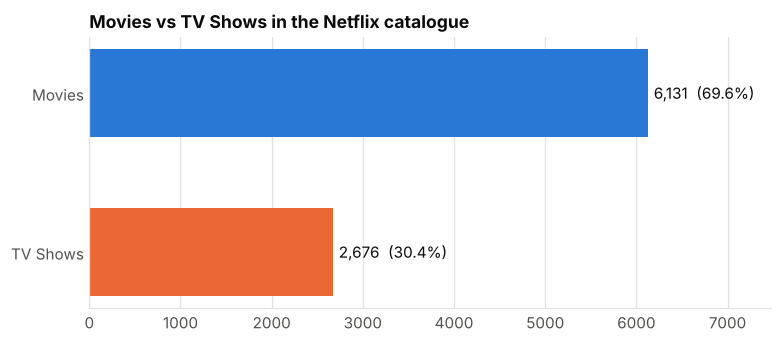

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(["TV Shows", "Movies"], [type_counts["TV Show"], type_counts["Movie"]],
        color=[ORANGE, BLUE], height=0.55)
for y, (name, v) in enumerate([("TV Show", type_counts["TV Show"]), ("Movie", type_counts["Movie"])]):
    ax.text(v + 60, y, f"{v:,}  ({v / n:.1%})", va="center", color=INK)
ax.set_title("Movies vs TV Shows in the Netflix catalogue")
ax.set_xlim(0, type_counts.max() * 1.22)
style_ax(ax, grid_axis="x")
plt.show()

type        Movie  TV Show  tv_share_%
year_added                            
2014           19        5        20.8
2015           56       26        31.7
2016          253      176        41.0
2017          839      349        29.4
2018         1237      412        25.0
2019         1424      592        29.4
2020         1284      595        31.7
2021          993      505        33.7

Type by period added:
 type        Movie  TV Show
year_added                
2008-2016     354      213
2017-2018    2076      761
2019-2021    3701     1692

Chi-square = 33.3, dof = 2, p = 5.74e-08, Cramer's V = 0.062


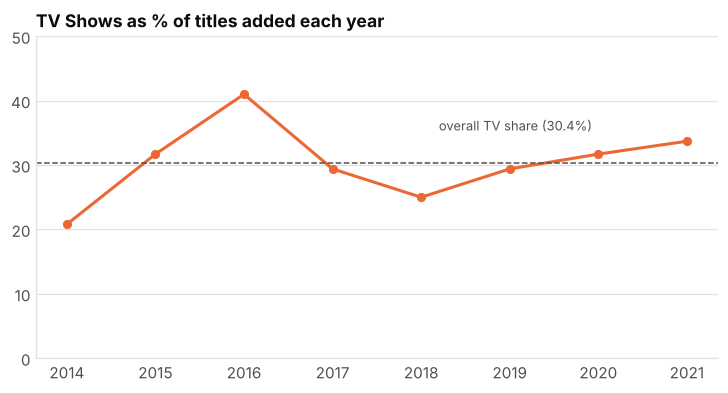

In [13]:
# ---- Does the Movie / TV mix change over time? ----
ct_year = pd.crosstab(df["year_added"], df["type"]).loc[2014:2021]
ct_year.index = ct_year.index.astype(int)
ct_year["tv_share_%"] = (ct_year["TV Show"] / (ct_year["Movie"] + ct_year["TV Show"]) * 100).round(1)
print(ct_year)

# Chi-square test of independence between type and period added
era = pd.cut(df["year_added"].astype(float), bins=[2007, 2016, 2018, 2021],
             labels=["2008-2016", "2017-2018", "2019-2021"])
ct_era = pd.crosstab(era, df["type"])
chi2, p, dof, _ = stats.chi2_contingency(ct_era)
cramers_v = np.sqrt(chi2 / (ct_era.values.sum() * (min(ct_era.shape) - 1)))
print("\nType by period added:\n", ct_era)
print(f"\nChi-square = {chi2:.1f}, dof = {dof}, p = {p:.2e}, Cramer's V = {cramers_v:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(ct_year.index, ct_year["tv_share_%"], color=ORANGE, linewidth=2, marker="o", markersize=5)
ax.axhline(type_counts["TV Show"] / n * 100, color=MUTED, linestyle="--", linewidth=1)
ax.text(2018.2, type_counts["TV Show"] / n * 100 + 5, "overall TV share (30.4%)", color=MUTED, fontsize=8.5)
ax.set_title("TV Shows as % of titles added each year")
ax.set_ylim(0, 50)
style_ax(ax)
plt.show()


**Interpretation**
- The TV Show share has **not been constant**: it was highest in 2016 (41 %), dropped to a low of 25 % in 2018, and has **risen steadily since** (29 % → 32 % → 34 % in 2019–2021).
- The chi-square test says type and period are **statistically related** (p < 0.001), but **Cramér's V = 0.06 is a very small effect**: the Movie/TV mix changed only modestly over time. Movies remain the majority in every year.


In [14]:
# ---- Movie runtime and TV seasons ----
movie_min = df.loc[df["type"] == "Movie", "duration"].str.extract(r"(\d+)")[0].astype(float).rename("minutes")
tv_seasons = df.loc[df["type"] == "TV Show", "duration"].str.extract(r"(\d+)")[0].astype(float).rename("seasons")

print("Movie runtime (minutes):")
print(movie_min.describe().round(1))
print("\nTV Show seasons:")
print(tv_seasons.describe().round(2))
print("\nTV Shows by number of seasons (%):")
print(tv_seasons.clip(upper=5).value_counts(normalize=True).sort_index().mul(100).round(1).rename({5.0: "5+"}).rename_axis("seasons").rename("% of shows"))

Movie runtime (minutes):
count    6131.0
mean       99.6
std        28.3
min         3.0
25%        87.0
50%        98.0
75%       114.0
max       312.0
Name: minutes, dtype: float64

TV Show seasons:
count    2676.00
mean        1.76
std         1.58
min         1.00
25%         1.00
50%         1.00
75%         2.00
max        17.00
Name: seasons, dtype: float64

TV Shows by number of seasons (%):
seasons
1.0    67.0
2.0    15.9
3.0     7.4
4.0     3.6
5+      6.1
Name: % of shows, dtype: float64



**Interpretation:** a typical Netflix movie runs **~98 minutes (median; middle 50 % between 87 and 114 min)**. TV content is mostly short-lived: **67 % of TV Shows have just one season**, and only ~6 % have five or more. That fits the catalogue being dominated by recent additions.


## Question 3 – Which countries contribute the most content?

**Column:** `country` → **Analysis:** rank the top 10 countries.

**How multi-country titles are handled.** Many titles are co-productions, e.g. `"United States, India, South Korea"`. Taking the whole string as one "country" would be wrong. Instead we:
1. **Split** the string on commas and strip spaces → a list of countries per title.
2. **Explode** the list so a co-production gets one row per country (the title counts **once for each country involved**).
3. **Exclude `"Unknown"`**: it is a missing-value placeholder, not a country. We report how many titles it affects.

Because of step 2, the percentages are "% of titles that involve this country" and **do not add up to 100 %**.

In [15]:
# 1) split into a clean list of countries per title
df["country_list"] = df["country"].str.split(",").apply(lambda lst: [c.strip() for c in lst if c.strip()])

# 2) one row per (title, country)
countries = (df[["show_id", "type", "year_added", "country_list"]]
               .explode("country_list").rename(columns={"country_list": "country_name"}))

# 3) drop the "Unknown" placeholder
known = countries[countries["country_name"] != "Unknown"]

n_titles = len(df)
n_unknown = (df["country"] == "Unknown").sum()
n_known_titles = n_titles - n_unknown
n_multi = (df["country_list"].apply(len) > 1).sum()
print(f"Titles in dataset                : {n_titles:,}")
print(f"Titles with unknown country      : {n_unknown:,} ({n_unknown / n_titles:.1%})  -> excluded from ranking")
print(f"Titles with a known country      : {n_known_titles:,}")
print(f"Multi-country co-productions     : {n_multi:,} ({n_multi / n_known_titles:.1%} of known-country titles)")
print(f"Distinct countries               : {known['country_name'].nunique()}")
print(f"Country-title links (after split): {len(known):,}")

Titles in dataset                : 8,807
Titles with unknown country      : 831 (9.4%)  -> excluded from ranking
Titles with a known country      : 7,976
Multi-country co-productions     : 1,315 (16.5% of known-country titles)
Distinct countries               : 122
Country-title links (after split): 10,012



**Interpretation:** 831 titles (9.4 %) have no country and are excluded; **7,976 titles remain**, spread over **122 countries**. About **1 in 6 (16.5 %) are co-productions**, so splitting the field matters: it adds ~2,000 country-title links beyond the 7,976 titles.


In [16]:
country_counts = known.groupby("country_name")["show_id"].nunique().sort_values(ascending=False)

top10 = country_counts.head(10).to_frame("titles")
top10["% of known-country titles"] = (top10["titles"] / n_known_titles * 100).round(1)
top10["% of all titles"] = (top10["titles"] / n_titles * 100).round(1)
top10.index.name = "country"
top10.insert(0, "rank", range(1, 11))

# type split for the top 10
type_split = (known[known["country_name"].isin(top10.index)]
                .groupby(["country_name", "type"])["show_id"].nunique().unstack(fill_value=0)
                .reindex(top10.index))
top10["movies"] = type_split["Movie"]
top10["tv_shows"] = type_split["TV Show"]
top10["tv_share_%"] = (top10["tv_shows"] / top10["titles"] * 100).round(1)
print(top10)

share_top10 = country_counts.head(10).sum() / country_counts.sum()
print(f"\nTop-10 countries account for {share_top10:.1%} of all country-title links.")
print(f"Countries with fewer than 10 titles: {(country_counts < 10).sum()} of {len(country_counts)}")

                rank  titles  % of known-country titles  % of all titles  movies  tv_shows  tv_share_%
country                                                                                               
United States      1    3690                       46.3             41.9    2752       938        25.4
India              2    1046                       13.1             11.9     962        84         8.0
United Kingdom     3     806                       10.1              9.2     534       272        33.7
Canada             4     445                        5.6              5.1     319       126        28.3
France             5     393                        4.9              4.5     303        90        22.9
Japan              6     318                        4.0              3.6     119       199        62.6
Spain              7     232                        2.9              2.6     171        61        26.3
South Korea        8     231                        2.9              2.6 


**Interpretation**
- **The United States leads by a wide margin: 3,690 titles, involved in 46 % of known-country titles**, more than three times India (1,046; 13.1 %).
- **Ranking:** 1 US, 2 India, 3 UK (806), 4 Canada (445), 5 France (393), 6 Japan (318), 7 Spain (232), 8 South Korea (231), 9 Germany (226), 10 Mexico (169).
- **Concentration:** the top 10 countries account for **75.5 %** of all country-title links, while **67 of the 122 countries have fewer than 10 titles**: a long tail of very small contributors.
- **Different countries specialise in different formats.** Netflix titles from **South Korea (74 % TV) and Japan (63 % TV)** are mostly series, while **India is overwhelmingly movies (92 %)**.


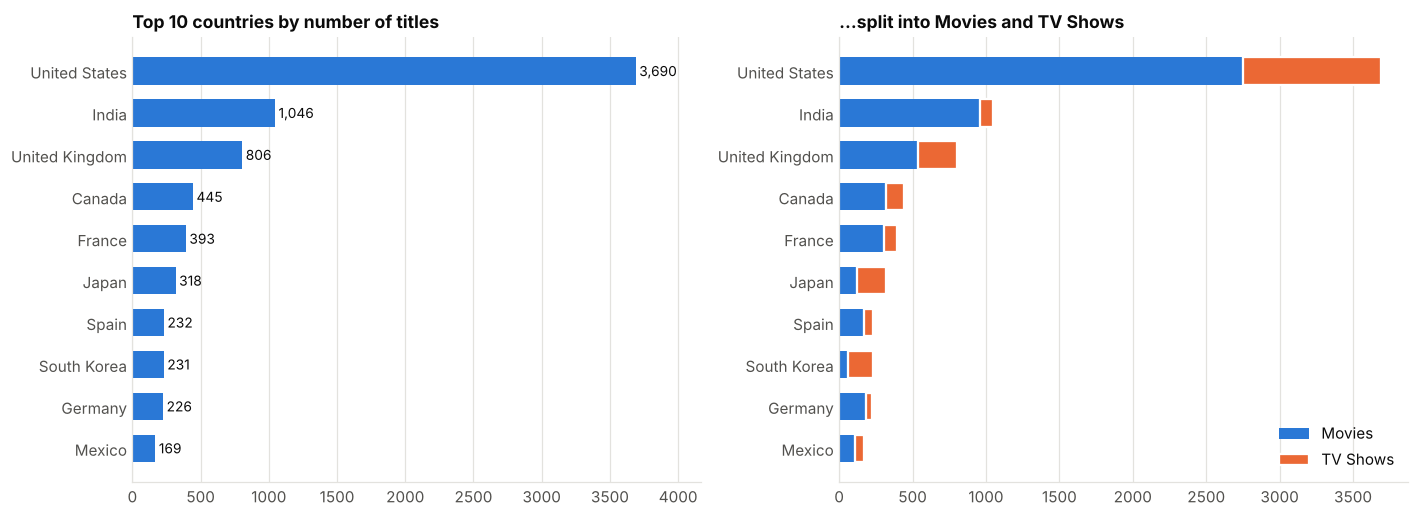

In [17]:
order = top10.index[::-1]          # reverse so the largest bar is at the top
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1]})

# (a) Ranking
ax = axes[0]
ax.barh(order, top10.loc[order, "titles"], color=BLUE, height=0.65)
for y, v in enumerate(top10.loc[order, "titles"]):
    ax.text(v + 25, y, f"{v:,}", va="center", fontsize=9, color=INK)
ax.set_title("Top 10 countries by number of titles")
ax.set_xlim(0, top10["titles"].max() * 1.13)
style_ax(ax, grid_axis="x")

# (b) Movies vs TV Shows within each country
ax = axes[1]
ax.barh(order, top10.loc[order, "movies"], color=BLUE, height=0.65, label="Movies")
ax.barh(order, top10.loc[order, "tv_shows"], left=top10.loc[order, "movies"], color=ORANGE,
        height=0.65, label="TV Shows", edgecolor="white", linewidth=1.5)
ax.set_title("...split into Movies and TV Shows")
ax.legend(frameon=False, loc="lower right")
style_ax(ax, grid_axis="x")
plt.tight_layout(); plt.show()

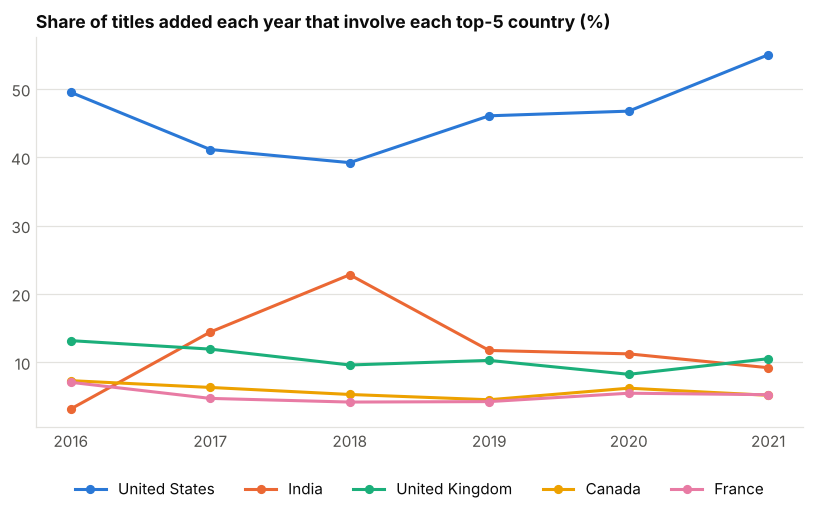

country_name,United States,India,United Kingdom,Canada,France
year_added,,,,,
2016,49.5,3.2,13.2,7.3,7.1
2017,41.1,14.4,11.9,6.3,4.7
2018,39.2,22.8,9.6,5.3,4.2
2019,46.1,11.7,10.3,4.5,4.3
2020,46.8,11.2,8.2,6.2,5.5
2021,55.0,9.2,10.5,5.2,5.3


In [18]:
# ---- Trend: share of each year's titles involving the top-5 countries ----
top5 = list(top10.index[:5])
years = list(range(2016, 2022))

titles_per_year = known.groupby("year_added")["show_id"].nunique()
share = (known[known["country_name"].isin(top5)]
           .groupby(["year_added", "country_name"])["show_id"].nunique().unstack(fill_value=0)
           .loc[years, top5].div(titles_per_year.loc[years], axis=0) * 100)
share.index = share.index.astype(int)

fig, ax = plt.subplots(figsize=(9, 4.6))
for colour, c in zip(SERIES, top5):
    ax.plot(share.index, share[c], color=colour, linewidth=2, marker="o", markersize=5, label=c)
ax.set_title("Share of titles added each year that involve each top-5 country (%)")
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
style_ax(ax)
plt.show()
share.round(1)


**Interpretation:** the US share dipped to ~39 % in 2018 and has risen since, to **55 % of 2021's titles**. India's share spiked in 2018 (22.8 %) and has settled around 9–12 %. The UK, Canada and France hold smaller, fairly steady shares (4–13 %). Note that 2016 shares rest on only a few hundred titles, so early-year movements are less reliable. (Percentages can sum to more than 100 % because co-productions count for every country involved.)


In [19]:
# ---- Most common co-production pairs ----
pairs = Counter()
for lst in df.loc[df["country_list"].apply(len) > 1, "country_list"]:
    lst = [c for c in lst if c != "Unknown"]
    for a, b in combinations(sorted(set(lst)), 2):
        pairs[(a, b)] += 1
pd.DataFrame([(f"{a} + {b}", c) for (a, b), c in pairs.most_common(8)], columns=["country pair", "joint titles"])

,country pair,joint titles
0,United Kingdom + United States,279
1,Canada + United States,217
2,France + United States,125
3,Germany + United States,88
4,France + United Kingdom,67
5,Japan + United States,63
6,Canada + United Kingdom,58
7,Belgium + France,57



**Interpretation:** the most common collaborations all involve the US: **UK + US (279 titles)** and **Canada + US (217)** lead, followed by France + US and Germany + US. The first non-US pair is France + UK (67).


## Question 4 – Which genres dominate Netflix's library?

**Column:** `listed_in` → **Analysis:** rank the most common genres.

**What the code does**
- `listed_in` holds several comma-separated genre tags per title (e.g. `"Dramas, International Movies"`), so we use the same **split → strip → explode** pattern as for countries.
- A title with three tags counts once for each tag, so genre percentages are "% of titles carrying this tag" and don't sum to 100 %.
- We rank overall, then separately for **Movies** and **TV Shows** (their genre vocabularies differ, e.g. *Dramas* vs *TV Dramas*).
- We measure **how many tags each title has**, find the most frequent **tag pairs** that appear together, and track the **share of the top-5 genres over time**.

> Note: *International Movies* / *International TV Shows* are really "non-English-language / non-US" labels rather than content genres. They're kept in the ranking (they are in the data) but interpreted with that in mind.

In [20]:
df["genre_list"] = df["listed_in"].str.split(",").apply(lambda lst: [g.strip() for g in lst if g.strip()])
genres = (df[["show_id", "type", "year_added", "genre_list"]]
            .explode("genre_list").rename(columns={"genre_list": "genre"}))

genre_counts = genres.groupby("genre")["show_id"].nunique().sort_values(ascending=False)
top_genres = genre_counts.head(15).to_frame("titles")
top_genres["% of all titles"] = (top_genres["titles"] / len(df) * 100).round(1)
top_genres.insert(0, "rank", range(1, 16))

print(f"Distinct genre tags: {genre_counts.shape[0]}")
print(f"Tags per title -> mean {df['genre_list'].apply(len).mean():.2f}, "
      f"median {df['genre_list'].apply(len).median():.0f}, max {df['genre_list'].apply(len).max()}")
print(f"Top-5 tags make up {genre_counts.head(5).sum() / genre_counts.sum():.1%} of all tag assignments; "
      f"top-10 make up {genre_counts.head(10).sum() / genre_counts.sum():.1%}")
top_genres

Distinct genre tags: 42
Tags per title -> mean 2.19, median 2, max 3
Top-5 tags make up 47.0% of all tag assignments; top-10 make up 65.8%


,rank,titles,% of all titles
genre,,,
International Movies,1,2752,31.2
Dramas,2,2427,27.6
Comedies,3,1674,19.0
International TV Shows,4,1351,15.3
Documentaries,5,869,9.9
Action & Adventure,6,859,9.8
TV Dramas,7,763,8.7
Independent Movies,8,756,8.6
Children & Family Movies,9,641,7.3



**Interpretation**
- The most common tags are **International Movies (2,752 titles, 31 %)**, **Dramas (2,427; 28 %)**, **Comedies (1,674; 19 %)**, **International TV Shows (1,351; 15 %)** and **Documentaries (869; 10 %)**.
- Titles carry on average **2.2 tags** (max 3), and the **top 10 of 42 tags make up ~66 % of all tag assignments**, so the catalogue is concentrated in a handful of broad genres.
- *International* is a label for non-US / non-English content more than a genre, which is consistent with the country results.


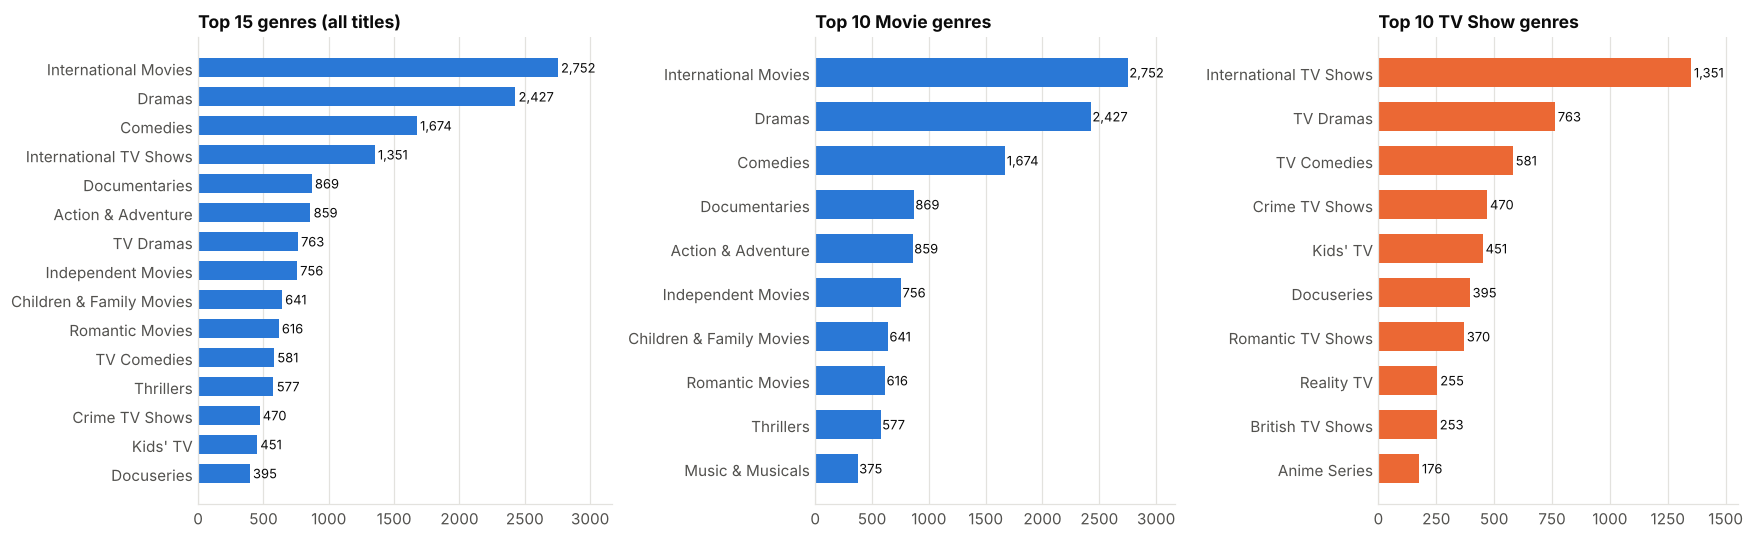

In [21]:
# ---- Ranking separately for Movies and TV Shows ----
by_type_genre = genres.groupby(["type", "genre"])["show_id"].nunique()
top_movie = by_type_genre["Movie"].sort_values(ascending=False).head(10)
top_tv = by_type_genre["TV Show"].sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1.15, 1, 1]})

# overall top 15
ax = axes[0]
t = top_genres["titles"][::-1]
ax.barh(t.index, t.values, color=BLUE, height=0.65)
for y, v in enumerate(t.values):
    ax.text(v + 25, y, f"{v:,}", va="center", fontsize=8.5)
ax.set_title("Top 15 genres (all titles)"); ax.set_xlim(0, t.max() * 1.15)
style_ax(ax, "x")

for ax, data, colour, title in ((axes[1], top_movie, BLUE, "Top 10 Movie genres"),
                                (axes[2], top_tv, ORANGE, "Top 10 TV Show genres")):
    d = data[::-1]
    ax.barh(d.index, d.values, color=colour, height=0.65)
    for y, v in enumerate(d.values):
        ax.text(v + 12, y, f"{v:,}", va="center", fontsize=8.5)
    ax.set_title(title); ax.set_xlim(0, d.max() * 1.15)
    style_ax(ax, "x")
plt.tight_layout(); plt.show()


**Interpretation:** among **Movies**, the order is International Movies > Dramas > Comedies > Documentaries > Action & Adventure. Among **TV Shows**, it is International TV Shows > TV Dramas > TV Comedies > Crime TV Shows > Kids' TV. Drama and comedy lead in both formats; the TV list also has distinct niches (Kids' TV, Reality TV, Anime Series).


In [22]:
# ---- Which genres are most often combined? ----
gp = Counter()
for lst in df["genre_list"]:
    for a, b in combinations(sorted(set(lst)), 2):
        gp[(a, b)] += 1
pd.DataFrame([(f"{a} + {b}", c) for (a, b), c in gp.most_common(8)], columns=["genre pair", "joint titles"])

,genre pair,joint titles
0,Dramas + International Movies,1483
1,Comedies + International Movies,804
2,Dramas + Independent Movies,588
3,International TV Shows + TV Dramas,514
4,Comedies + Dramas,502
5,Action & Adventure + International Movies,398
6,International Movies + Romantic Movies,372
7,International TV Shows + Romantic TV Shows,315



**Interpretation:** the single most common combination is **Dramas + International Movies (1,483 titles)**, followed by Comedies + International Movies (804) and Dramas + Independent Movies (588). Genres are strongly overlapping, not mutually exclusive.


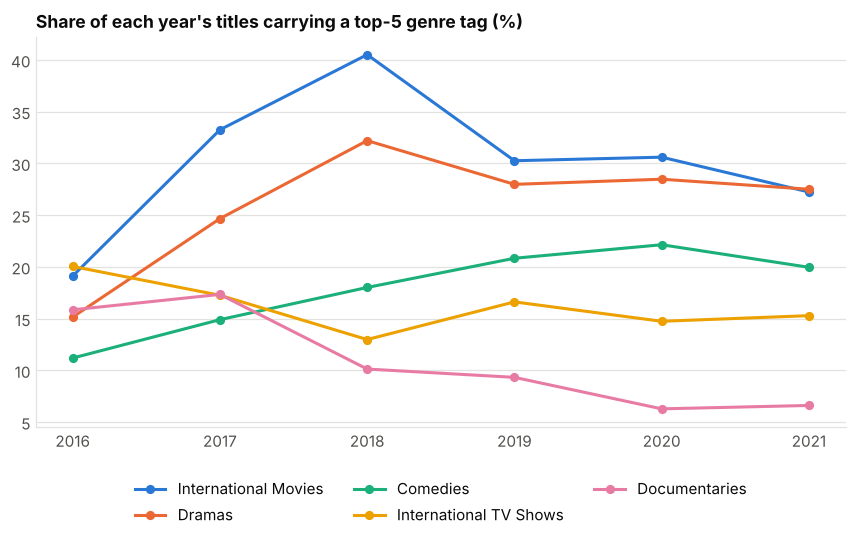

genre,International Movies,Dramas,Comedies,International TV Shows,Documentaries
year_added,,,,,
2016,19.1,15.2,11.2,20.0,15.9
2017,33.2,24.7,14.9,17.3,17.3
2018,40.5,32.2,18.0,13.0,10.1
2019,30.3,28.0,20.8,16.6,9.3
2020,30.6,28.5,22.1,14.7,6.3
2021,27.2,27.5,20.0,15.3,6.6


In [23]:
# ---- Trend: share of each year's titles that carry each top-5 genre tag ----
top5g = list(genre_counts.head(5).index)
years = list(range(2016, 2022))
n_per_year = df.groupby("year_added").size()

gshare = (genres[genres["genre"].isin(top5g)]
            .groupby(["year_added", "genre"])["show_id"].nunique().unstack(fill_value=0)
            .loc[years, top5g].div(n_per_year.loc[years], axis=0) * 100)
gshare.index = gshare.index.astype(int)

fig, ax = plt.subplots(figsize=(9.5, 4.6))
for colour, g in zip(SERIES, top5g):
    ax.plot(gshare.index, gshare[g], color=colour, linewidth=2, marker="o", markersize=5, label=g)
ax.set_title("Share of each year's titles carrying a top-5 genre tag (%)")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
style_ax(ax)
plt.show()
gshare.round(1)


**Interpretation:** the genre mix has shifted. **Documentaries fell from ~17 % of titles added in 2017 to ~7 % in 2021**, **Comedies grew from 11 % (2016) to 20–22 %** and **International Movies and Dramas peaked in 2018** (40 % and 32 %) before settling near 27 %. Early years (2016) are based on few titles, so focus on 2017 onwards.


## Question 5 – How has the distribution of release years changed?

**Column:** `release_year` → **Analysis:** examine the distribution of original release years.

**What the code does**
- **Descriptive statistics**: mean, median, quartiles, standard deviation, **skewness** (negative = long tail towards old years) and **kurtosis**.
- **Decade table**: `release_year // 10 * 10` groups years into decades; we show counts and cumulative share.
- **Recency shares**: what % of the catalogue was released in 2010+, 2015+, 2018+?
- **Histogram / bar charts**: full history (1925–2021) and a zoom on 2000–2021, where almost all titles sit.
- **Content age at addition** = `year_added − release_year`. It tells us whether Netflix mostly adds *new* releases or *older* back-catalogue titles, and how that changed.
- **Mann–Whitney U test** compares Movie vs TV Show release years. We use it instead of a t-test because the distribution is strongly skewed (not bell-shaped).

In [24]:
ry = df["release_year"]
desc = ry.describe().round(1)
desc["mode"] = ry.mode().iloc[0]
desc["skewness"] = round(ry.skew(), 2)
desc["kurtosis"] = round(ry.kurt(), 2)
print(desc)

print()
for yr in (2000, 2010, 2015, 2018, 2020):
    print(f"Released in {yr} or later: {(ry >= yr).mean():6.1%}   ({(ry >= yr).sum():,} titles)")

# ---- By decade ----
decade = (ry // 10 * 10).value_counts().sort_index().to_frame("titles")
decade["percent"] = (decade["titles"] / len(df) * 100).round(1)
decade["cumulative_%"] = decade["percent"].cumsum().round(1)
decade.index = [f"{d}s" for d in decade.index]
print()
print(decade)

count       8807.00
mean        2014.20
std            8.80
min         1925.00
25%         2013.00
50%         2017.00
75%         2019.00
max         2021.00
mode        2018.00
skewness      -3.45
kurtosis      16.23
Name: release_year, dtype: float64

Released in 2000 or later:  94.0%   (8,282 titles)
Released in 2010 or later:  84.8%   (7,472 titles)
Released in 2015 or later:  70.6%   (6,216 titles)
Released in 2018 or later:  42.3%   (3,722 titles)
Released in 2020 or later:  17.5%   (1,545 titles)

       titles  percent  cumulative_%
1920s       1      0.0           0.0
1940s      15      0.2           0.2
1950s      11      0.1           0.3
1960s      25      0.3           0.6
1970s      70      0.8           1.4
1980s     129      1.5           2.9
1990s     274      3.1           6.0
2000s     810      9.2          15.2
2010s    5927     67.3          82.5
2020s    1545     17.5         100.0



**Interpretation**
- The distribution is **extremely left-skewed (skewness −3.45)** with a heavy tail (kurtosis 16.2): the **median is 2017**, the **mode is 2018**, and the mean (2014) is pulled down by a small number of very old titles (earliest: 1925).
- **The catalogue is overwhelmingly recent:** **84.8 % of titles were released in 2010 or later**, 70.6 % in 2015 or later, and 42.3 % in 2018 or later. The **2010s alone are 67.3 %**, and pre-1980 content is only ~1.4 %.


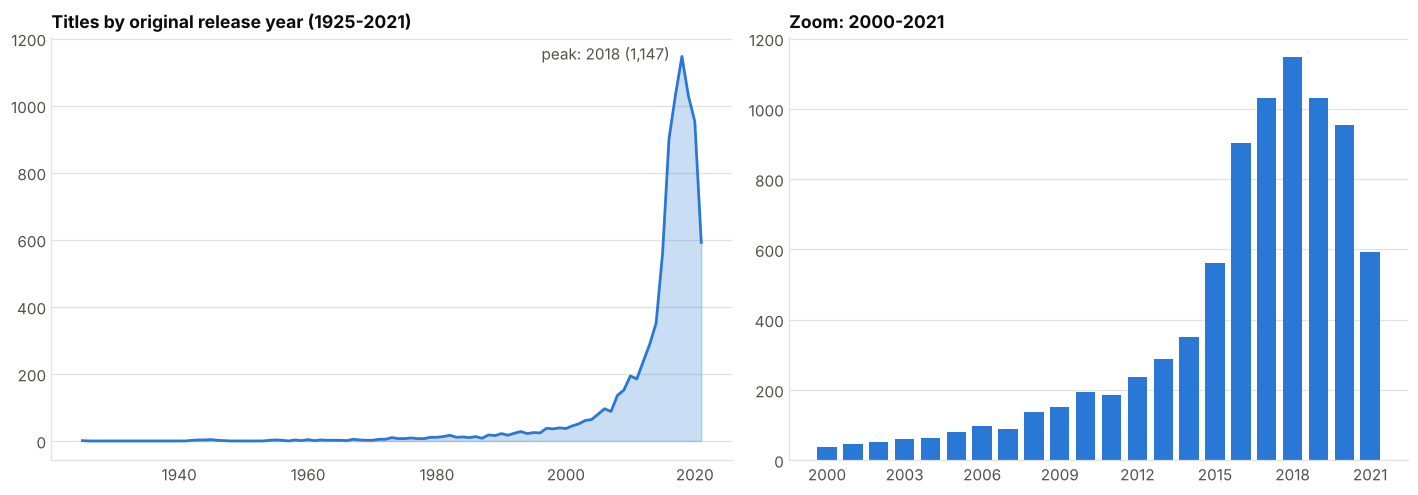

In [25]:
by_year = ry.value_counts().sort_index()
by_year = by_year.reindex(range(ry.min(), ry.max() + 1), fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})

# (a) Whole history
ax = axes[0]
ax.fill_between(by_year.index, by_year.values, color=BLUE, alpha=0.25)
ax.plot(by_year.index, by_year.values, color=BLUE, linewidth=1.8)
peak = by_year.idxmax()
ax.annotate(f"peak: {peak} ({by_year.max():,})", (peak, by_year.max()), textcoords="offset points",
            xytext=(-8, -2), ha="right", color=MUTED)
ax.set_title("Titles by original release year (1925-2021)")
style_ax(ax)

# (b) Zoom on 2000-2021
ax = axes[1]
z = by_year.loc[2000:]
ax.bar(z.index, z.values, color=BLUE, width=0.75)
ax.set_title("Zoom: 2000-2021")
ax.set_xticks(range(2000, 2022, 3))
style_ax(ax)
plt.tight_layout(); plt.show()


**Interpretation:** the release-year curve is almost flat until the 1990s, then rises sharply from ~2005 and peaks in **2018 (1,147 titles)**. The drop after 2018 is partly real (2020–2021 releases are fewer in the data) and the final bar (2021) is again partial. Older "classic" content exists, but it is a thin tail.


In [26]:
# ---- How old is content when Netflix adds it? ----
df["age_at_addition"] = df["year_added"] - df["release_year"]       # <NA> if date_added is missing
age = df["age_at_addition"].dropna().astype(int)

print(f"Titles where year_added < release_year (data oddity): {(age < 0).sum()}")
print(age.describe().round(2))
print(f"\nAdded in the same year as release : {(age == 0).mean():.1%}")
print(f"Added within 1 year of release     : {(age <= 1).mean():.1%}")
print(f"Added 5+ years after release       : {(age >= 5).mean():.1%}")
print(f"Added 10+ years after release      : {(age >= 10).mean():.1%}")

# trend: median age by year added
age_trend = (df.groupby("year_added")["age_at_addition"].median().astype(float).loc[2015:2021]
               .rename("median_age_years").to_frame())
age_trend["share_added_same_or_prev_year_%"] = (
    df[df["year_added"].between(2015, 2021)].groupby("year_added")["age_at_addition"]
      .apply(lambda s: (s <= 1).mean() * 100).round(1))
age_trend.index = age_trend.index.astype(int)
age_trend

Titles where year_added < release_year (data oddity): 14
count    8797.00
mean        4.69
std         8.79
min        -3.00
25%         0.00
50%         1.00
75%         5.00
max        93.00
Name: age_at_addition, dtype: float64

Added in the same year as release : 36.8%
Added within 1 year of release     : 55.0%
Added 5+ years after release       : 27.1%
Added 10+ years after release      : 15.2%


,median_age_years,share_added_same_or_prev_year_%
year_added,,
2015,0.0,81.7
2016,1.0,65.5
2017,1.0,59.8
2018,1.0,54.8
2019,1.0,51.6
2020,1.0,55.5
2021,1.0,50.8



**Interpretation**
- Netflix mostly adds **new content**: **36.8 % of titles were added in the same year they were released and 55 % within one year** (median age = 1 year).
- Still, a meaningful back-catalogue exists: **27 % were added 5+ years after release and 15 % are 10+ years old** (max 93 years).
- The **share of "fresh" titles has declined over time: from 65 % (2016) to ~51 % (2021)**, so more older content is being added as the library matures.
- 14 titles have `year_added` earlier than `release_year` (up to 3 years). This is a small data quirk (e.g. announced/pre-release listings) and doesn't change the results.


Median release year -> Movies: 2016, TV Shows: 2018
Mann-Whitney U = 5,820,528, p = 2.05e-105


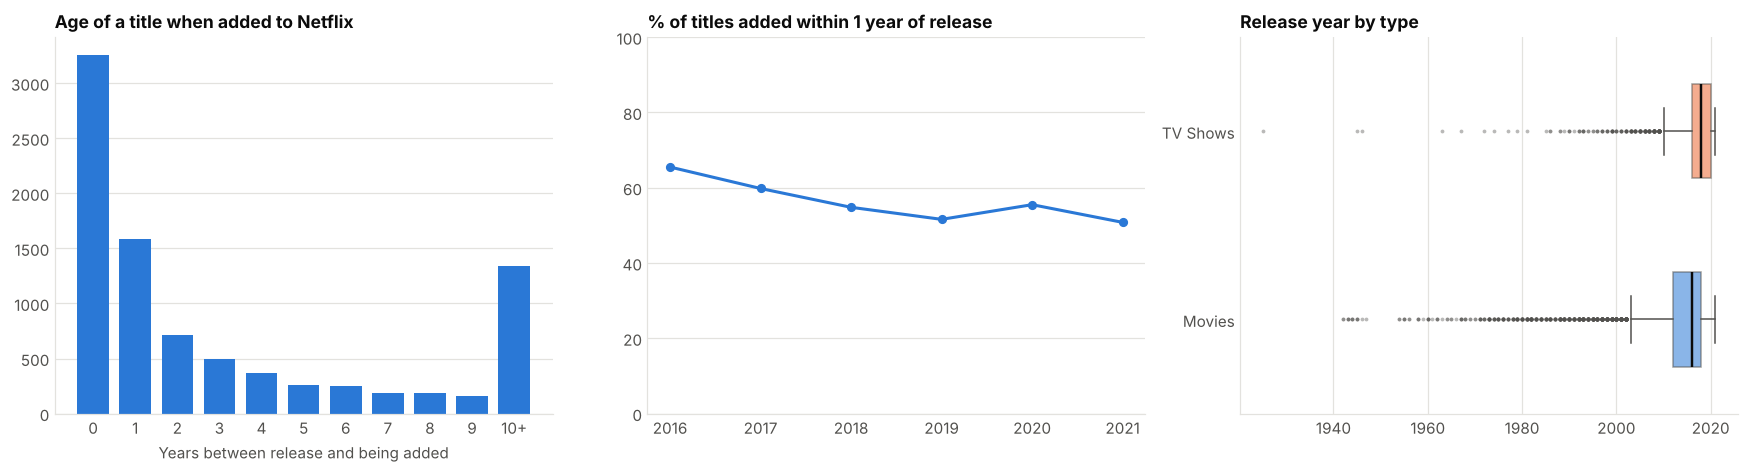

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

# (a) age distribution (capped at 10+)
ax = axes[0]
a = age.clip(0, 10).value_counts().sort_index()
ax.bar(a.index, a.values, color=BLUE, width=0.75)
ax.set_xticks(range(0, 11)); ax.set_xticklabels([str(i) for i in range(10)] + ["10+"])
ax.set_xlabel("Years between release and being added")
ax.set_title("Age of a title when added to Netflix")
style_ax(ax)

# (b) median age by year added
ax = axes[1]
recent = age_trend.loc[2016:]          # 2015 has only 82 titles, so it is left out of the chart
ax.plot(recent.index, recent["share_added_same_or_prev_year_%"], color=BLUE, linewidth=2, marker="o", markersize=5)
ax.set_title("% of titles added within 1 year of release")
ax.set_ylim(0, 100)
style_ax(ax)

# (c) release year by type (box plot)
ax = axes[2]
data = [df.loc[df["type"] == t, "release_year"] for t in ("Movie", "TV Show")]
bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.5,
                flierprops=dict(marker="o", markersize=2.5, markerfacecolor=MUTED, markeredgecolor="none", alpha=0.4),
                medianprops=dict(color=INK, linewidth=1.6), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for patch, colour in zip(bp["boxes"], (BLUE, ORANGE)):
    patch.set_facecolor(colour); patch.set_alpha(0.55); patch.set_edgecolor(MUTED)
ax.set_yticklabels(["Movies", "TV Shows"])
ax.set_title("Release year by type")
style_ax(ax, "x")
plt.tight_layout(); plt.show()

# ---- Movies vs TV Shows: is the release-year distribution different? ----
movies_ry, tv_ry = data
u, p = stats.mannwhitneyu(movies_ry, tv_ry, alternative="two-sided")
print(f"Median release year -> Movies: {movies_ry.median():.0f}, TV Shows: {tv_ry.median():.0f}")
print(f"Mann-Whitney U = {u:,.0f}, p = {p:.2e}")


**Interpretation:** the age chart confirms that the largest group is content added in its release year, with a second small bump for 10+ year-old titles. **TV Shows are newer than Movies** (median release year 2018 vs 2016); the difference is highly significant (Mann–Whitney p ≈ 10⁻¹⁰⁵), and Movies have a much longer tail of old titles.


## Summary of findings

| Question | Key finding |
|---|---|
| **Q1 – Library growth** | Almost nothing before 2016; **2016–2019 added 60 % of all titles**; peak in **2019 (2,016)**. Like-for-like 2021 is **+10 %** vs 2020, so additions have plateaued rather than collapsed. Busiest months: Oct–Dec. |
| **Q2 – Movies vs TV** | **Movies 69.6 % (6,131) vs TV Shows 30.4 % (2,676)**, roughly 2.3 : 1. TV share dipped to 25 % in 2018 and has recovered to ~34 %. |
| **Q3 – Countries** | **US 46 %** of known-country titles, then **India 13 %, UK 10 %**; top 10 = 75.5 % of links; Japan and South Korea are TV-heavy, India movie-heavy; 9.4 % of titles have unknown country. |
| **Q4 – Genres** | **International Movies, Dramas, Comedies, International TV Shows, Documentaries** lead; top 10 of 42 tags = 66 % of assignments; documentaries' share has been shrinking while comedies' has grown. |
| **Q5 – Release years** | Strongly left-skewed: **median 2017**, **85 % released since 2010**; 55 % of titles added within a year of release; the share of fresh content is slowly decreasing. |

### Caveats
- `date_added` ends on **2021-09-25**, so 2021 is partial in every year-based chart (use the like-for-like table for fair comparisons).
- Co-productions are counted once per country / genre, so those percentages overlap and sum to more than 100 %.
- `"Unknown"` country (9.4 %) is excluded from Q3. 10 titles have no `date_added` and are excluded from year-based analysis.
- All statistical tests show **association, not causation**. With ~8,800 rows even tiny effects are "significant", so we report effect sizes (e.g. Cramér's V) as well.